<a href="https://colab.research.google.com/github/irfan060606/Scikit-Learn-Cookbook/blob/main/Chapter_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter 7: Support Vector Machines and Kernel Methods

**Reference:** John Sukup, *scikit-learn Cookbook, Third Edition* (Chapter 7)

## Chapter overview

Support Vector Machines (SVMs) are supervised-learning models used for classification and regression. For classification, SVM looks for a decision boundary that separates classes while keeping the margin as wide as possible. The observations closest to this boundary are called **support vectors**.

This notebook follows the chapter's five main topics:

1. Introduction to SVMs
2. Kernel functions and their applications
3. Tuning SVM parameters
4. SVMs in high-dimensional spaces
5. Evaluating SVM models

The practical examples use scikit-learn datasets and synthetic data. Results can change when the data split or library version changes, so the notebook calculates metrics rather than assuming fixed results.

## 1. Introduction to SVMs

### Key ideas

- **Hyperplane / decision boundary:** the surface used to separate classes.
- **Margin:** the distance between the decision boundary and the closest training observations.
- **Support vectors:** observations that determine the position of the boundary and margin.
- **Soft margin:** allows some observations to be inside the margin or misclassified.
- **`C`:** controls the penalty for margin violations. A larger `C` penalizes errors more strongly; a smaller `C` allows a wider, more tolerant margin.

For a linear SVM, the separating boundary can be written as

\[
\mathbf{w}^{T}\mathbf{x}+b=0.
\]

A common conceptual objective is to keep \(\|\mathbf{w}\|\) small (which corresponds to a wider margin) while penalizing margin violations. In practice, scikit-learn's `SVC` optimizes this objective for the selected kernel and parameters.

### First example: visualize a linear SVM

We create a small two-class dataset so the boundary and support vectors can be plotted in two dimensions.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

X_blobs, y_blobs = make_blobs(
    n_samples=100, centers=2, cluster_std=1.7, random_state=42
)

# Scaling is included in the pipeline so preprocessing is learned from training data.
linear_svm = make_pipeline(
    StandardScaler(),
    SVC(kernel="linear", C=1.0)
)
linear_svm.fit(X_blobs, y_blobs)

svc_step = linear_svm.named_steps["svc"]
print("Number of support vectors:", int(svc_step.n_support_.sum()))
print("Support vectors by class:", svc_step.n_support_)

Number of support vectors: 5
Support vectors by class: [3 2]


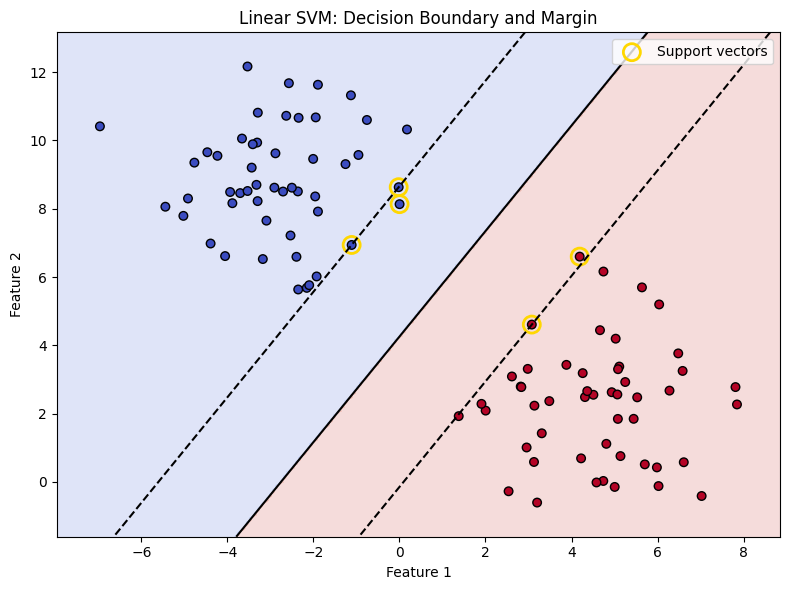

In [2]:
# Build a grid across the two features to visualize predictions and margins.
x_min, x_max = X_blobs[:, 0].min() - 1, X_blobs[:, 0].max() + 1
y_min, y_max = X_blobs[:, 1].min() - 1, X_blobs[:, 1].max() + 1
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 250),
    np.linspace(y_min, y_max, 250)
)
grid_points = np.c_[xx.ravel(), yy.ravel()]
decision_scores = linear_svm.decision_function(grid_points).reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, linear_svm.predict(grid_points).reshape(xx.shape),
             alpha=0.18, cmap="coolwarm")
plt.contour(xx, yy, decision_scores, levels=[-1, 0, 1],
            colors=["black", "black", "black"],
            linestyles=["--", "-", "--"], linewidths=1.5)
plt.scatter(X_blobs[:, 0], X_blobs[:, 1], c=y_blobs,
            cmap="coolwarm", edgecolor="black", s=38)
support_vectors_original_scale = (
    linear_svm.named_steps["standardscaler"].inverse_transform(svc_step.support_vectors_)
)
plt.scatter(support_vectors_original_scale[:, 0],
            support_vectors_original_scale[:, 1],
            s=150, facecolors="none", edgecolors="gold",
            linewidths=2, label="Support vectors")
plt.title("Linear SVM: Decision Boundary and Margin")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.tight_layout()
plt.show()

**How to read the plot:** the solid line is the decision boundary and the dashed lines show the margin levels. The highlighted circles indicate support vectors. Their locations matter directly to the learned boundary.

SVMs can also be used for regression. In Support Vector Regression (SVR), the model aims to fit a function while tolerating errors within an adjustable margin (often called the epsilon tube).

Test MAE on this illustrative dataset: 0.088
Test R² on this illustrative dataset: 0.976


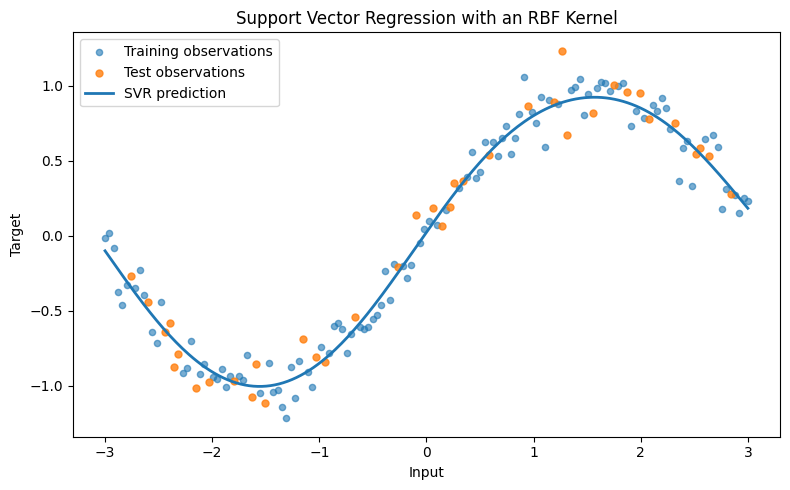

In [3]:
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split

rng = np.random.default_rng(2024)
X_reg = np.linspace(-3, 3, 150).reshape(-1, 1)
y_reg = np.sin(X_reg[:, 0]) + rng.normal(0, 0.12, size=len(X_reg))

X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg, y_reg, test_size=0.25, random_state=2024
)

svr_model = make_pipeline(
    StandardScaler(),
    SVR(kernel="rbf", C=10, epsilon=0.1)
)
svr_model.fit(X_reg_train, y_reg_train)
y_reg_pred = svr_model.predict(X_reg_test)

print(f"Test MAE on this illustrative dataset: {mean_absolute_error(y_reg_test, y_reg_pred):.3f}")
print(f"Test R² on this illustrative dataset: {r2_score(y_reg_test, y_reg_pred):.3f}")

X_curve = np.linspace(-3, 3, 300).reshape(-1, 1)
y_curve = svr_model.predict(X_curve)
order = np.argsort(X_curve[:, 0])

plt.figure(figsize=(8, 5))
plt.scatter(X_reg_train[:, 0], y_reg_train, s=20, alpha=0.6, label="Training observations")
plt.scatter(X_reg_test[:, 0], y_reg_test, s=25, alpha=0.8, label="Test observations")
plt.plot(X_curve[order, 0], y_curve[order], linewidth=2, label="SVR prediction")
plt.xlabel("Input")
plt.ylabel("Target")
plt.title("Support Vector Regression with an RBF Kernel")
plt.legend()
plt.tight_layout()
plt.show()

## 2. Kernel Functions and Their Applications

A kernel lets SVM model relationships that may not be separated well by a straight line in the original feature space. The kernel trick computes a similarity between observations as if they had been mapped into another feature space.

Three common choices in `SVC` are:

- **Linear:** a linear decision boundary in the supplied feature space.
- **Polynomial (`poly`):** allows curved boundaries influenced by the polynomial degree.
- **RBF (`rbf`):** a flexible, local similarity kernel that can create nonlinear boundaries.

No kernel is best for every dataset. Compare them using the same split and evaluation method. Here we use all four Iris features for the numeric comparison.

In [4]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

iris = load_iris()
X_iris, y_iris = iris.data, iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X_iris, y_iris, test_size=0.30, random_state=2024, stratify=y_iris
)

kernel_settings = [
    {"kernel": "linear", "C": 1.0},
    {"kernel": "poly", "degree": 3, "C": 1.0},
    {"kernel": "rbf", "C": 1.0, "gamma": "scale"},
]

kernel_results = []
kernel_models = {}

for settings in kernel_settings:
    model = make_pipeline(StandardScaler(), SVC(**settings))
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    svc = model.named_steps["svc"]
    kernel_name = settings["kernel"]
    kernel_models[kernel_name] = model
    kernel_results.append({
        "Kernel": kernel_name,
        "Test accuracy": accuracy_score(y_test, predictions),
        "Support vectors": int(svc.n_support_.sum())
    })

pd.DataFrame(kernel_results).sort_values(
    "Test accuracy", ascending=False
).reset_index(drop=True)

,Kernel,Test accuracy,Support vectors
0,linear,0.977778,21
1,rbf,0.933333,40
2,poly,0.888889,42


The table reports the results from this particular split. Accuracy shows the share of correct predictions; the support-vector count gives additional information about which training points define the SVM boundary. Neither value alone proves which model will generalize best on other data.

In [5]:
# Inspect one model's per-class performance.
iris_predictions = kernel_models["rbf"].predict(X_test)
print(classification_report(
    y_test, iris_predictions, target_names=iris.target_names, zero_division=0
))
print("Confusion matrix (rows = actual class, columns = predicted class):")
print(confusion_matrix(y_test, iris_predictions))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.93      0.87      0.90        15
   virginica       0.88      0.93      0.90        15

    accuracy                           0.93        45
   macro avg       0.93      0.93      0.93        45
weighted avg       0.93      0.93      0.93        45

Confusion matrix (rows = actual class, columns = predicted class):
[[15  0  0]
 [ 0 13  2]
 [ 0  1 14]]


### Visualize decision boundaries in two dimensions

For plotting, we use only petal length and petal width. These plots are two-feature demonstrations, so they are not directly comparable with the earlier models trained on all four features.

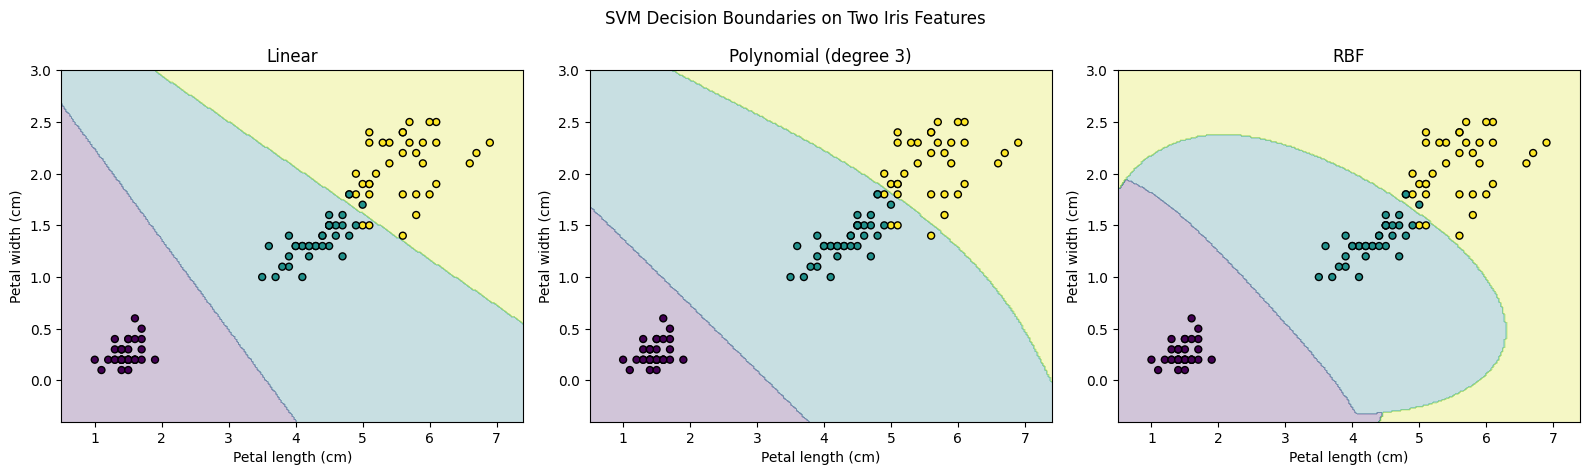

Linear: test accuracy = 0.956
Polynomial (degree 3): test accuracy = 0.933
RBF: test accuracy = 0.956


In [6]:
feature_indices = [2, 3]  # petal length and petal width
X_iris_2d = X_iris[:, feature_indices]

X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(
    X_iris_2d, y_iris, test_size=0.30, random_state=2024, stratify=y_iris
)

models_2d = {
    "Linear": make_pipeline(StandardScaler(), SVC(kernel="linear", C=1)),
    "Polynomial (degree 3)": make_pipeline(
        StandardScaler(), SVC(kernel="poly", degree=3, C=1)
    ),
    "RBF": make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1, gamma="scale"))
}

x_min, x_max = X_iris_2d[:, 0].min() - 0.5, X_iris_2d[:, 0].max() + 0.5
y_min, y_max = X_iris_2d[:, 1].min() - 0.5, X_iris_2d[:, 1].max() + 0.5
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 250),
    np.linspace(y_min, y_max, 250)
)
plot_grid = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, (name, model) in zip(axes, models_2d.items()):
    model.fit(X_train_2d, y_train_2d)
    grid_labels = model.predict(plot_grid).reshape(xx.shape)
    ax.contourf(xx, yy, grid_labels, alpha=0.25, cmap="viridis")
    ax.scatter(X_train_2d[:, 0], X_train_2d[:, 1],
               c=y_train_2d, cmap="viridis", edgecolor="black", s=25)
    ax.set_title(name)
    ax.set_xlabel("Petal length (cm)")
    ax.set_ylabel("Petal width (cm)")
plt.suptitle("SVM Decision Boundaries on Two Iris Features")
plt.tight_layout()
plt.show()

for name, model in models_2d.items():
    print(f"{name}: test accuracy = {accuracy_score(y_test_2d, model.predict(X_test_2d)):.3f}")

**Interpretation:** the linear kernel can only make linear boundaries in these two features. Polynomial and RBF kernels can make curved boundaries. Added flexibility can help when the true pattern is nonlinear, but can also overfit if parameters are poorly chosen.

## 3. Tuning SVM Parameters

Important parameters include:

- **`C`:** controls the trade-off between margin width and training errors. Larger values put a stronger penalty on margin violations.
- **`kernel`:** chooses the similarity function (`linear`, `poly`, or `rbf`).
- **`degree`:** polynomial degree; it matters for the polynomial kernel.
- **`gamma`:** controls the influence range of individual training points for RBF and some other kernels.

`GridSearchCV` evaluates a list of parameter combinations with cross-validation. Scaling is part of the pipeline so each fold learns its scaling only from that fold's training data.

In [7]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

svm_pipeline = make_pipeline(StandardScaler(), SVC())

# Separate grids avoid testing parameters that do not apply to a given kernel.
parameter_grid = [
    {"svc__kernel": ["linear"], "svc__C": [0.1, 1, 10]},
    {"svc__kernel": ["rbf"], "svc__C": [0.1, 1, 10],
     "svc__gamma": ["scale", "auto"]},
    {"svc__kernel": ["poly"], "svc__C": [0.1, 1, 10],
     "svc__degree": [2, 3, 4], "svc__gamma": ["scale"]}
]

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=2024)
grid_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=parameter_grid,
    cv=cv_strategy,
    scoring="accuracy",
    n_jobs=-1
)
grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print(f"Best mean cross-validation accuracy: {grid_search.best_score_:.3f}")
best_svm = grid_search.best_estimator_
best_test_predictions = best_svm.predict(X_test)
print(f"Test accuracy of selected model: {accuracy_score(y_test, best_test_predictions):.3f}")

Best parameters: {'svc__C': 1, 'svc__kernel': 'linear'}
Best mean cross-validation accuracy: 0.981
Test accuracy of selected model: 0.978


### Explore the effect of `C` for an RBF kernel

The next experiment changes `C` while holding the kernel fixed. Cross-validation estimates performance for each value. The selected value should be evaluated on a separate test set after tuning.

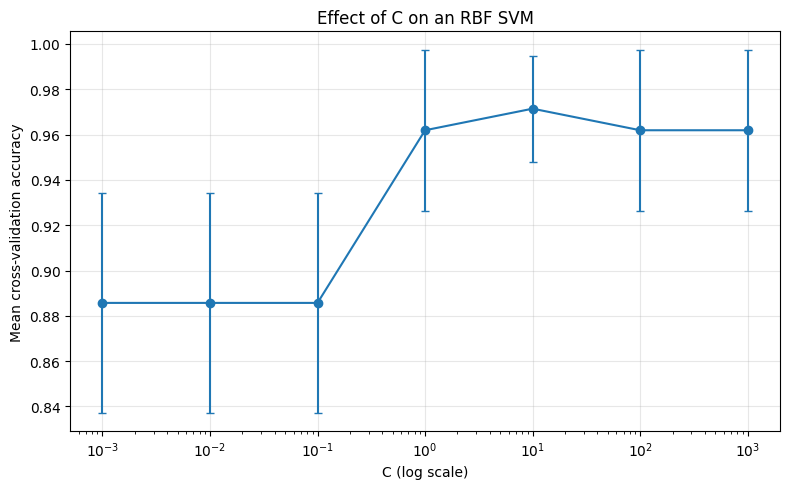

Best C: 10.0
Best CV accuracy: 0.971


In [8]:
c_values = np.logspace(-3, 3, 7)
c_search = GridSearchCV(
    estimator=make_pipeline(StandardScaler(), SVC(kernel="rbf")),
    param_grid={"svc__C": c_values},
    cv=cv_strategy,
    scoring="accuracy",
    n_jobs=-1
)
c_search.fit(X_train, y_train)

cv_means = c_search.cv_results_["mean_test_score"]
cv_stds = c_search.cv_results_["std_test_score"]

plt.figure(figsize=(8, 5))
plt.errorbar(c_values, cv_means, yerr=cv_stds, marker="o", capsize=3)
plt.xscale("log")
plt.xlabel("C (log scale)")
plt.ylabel("Mean cross-validation accuracy")
plt.title("Effect of C on an RBF SVM")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Best C:", c_search.best_params_["svc__C"])
print(f"Best CV accuracy: {c_search.best_score_:.3f}")

**Good practice:** do not choose hyperparameters by looking at the test-set score repeatedly. Use cross-validation for selection, and reserve the test set for the final estimate. Grid search can be computationally expensive as the number of combinations grows.

## 4. SVMs in High-Dimensional Spaces

SVMs can be useful when a dataset has many features, such as text or sensor measurements. However, many features may be irrelevant or noisy, so performance still needs to be measured. This example uses a synthetic dataset with 1,000 features, including 50 informative features.

In [9]:
from sklearn.datasets import make_classification
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score

X_high, y_high = make_classification(
    n_samples=1000,
    n_features=1000,
    n_informative=50,
    n_redundant=0,
    random_state=2024
)

X_train_high, X_test_high, y_train_high, y_test_high = train_test_split(
    X_high, y_high, test_size=0.30, random_state=2024, stratify=y_high
)

high_dimensional_svm = make_pipeline(
    StandardScaler(),
    SVC(kernel="linear", C=1.0)
)
high_dimensional_svm.fit(X_train_high, y_train_high)
high_dim_predictions = high_dimensional_svm.predict(X_test_high)

print("Dataset shape:", X_high.shape)
print("Number of features:", X_high.shape[1])
print("Informative features generated:", 50)
print(f"Test accuracy: {accuracy_score(y_test_high, high_dim_predictions):.3f}")
print(classification_report(
    y_test_high, high_dim_predictions, zero_division=0
))

Dataset shape: (1000, 1000)
Number of features: 1000
Informative features generated: 50
Test accuracy: 0.580
              precision    recall  f1-score   support

           0       0.58      0.61      0.59       151
           1       0.58      0.55      0.57       149

    accuracy                           0.58       300
   macro avg       0.58      0.58      0.58       300
weighted avg       0.58      0.58      0.58       300



### Visualize the high-dimensional dataset with PCA

PCA projects data to two dimensions for a visual inspection. PCA preserves directions of high variance; those directions do not necessarily provide the best class separation. This visualization is descriptive and is not used to train or evaluate the high-dimensional SVM.

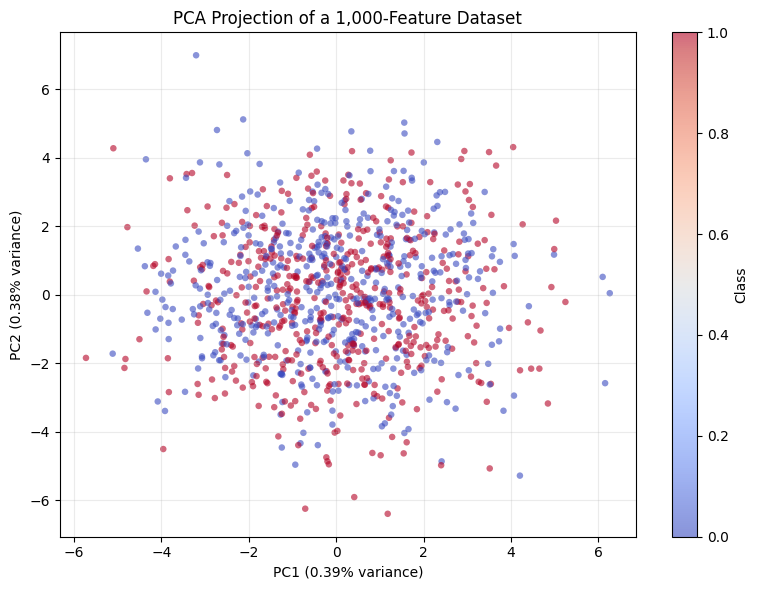

Variance explained by the first two components: 0.77%


In [10]:
# Standardize features before PCA so that scales do not dominate the projection.
X_high_scaled = StandardScaler().fit_transform(X_high)
pca = PCA(n_components=2, random_state=2024)
X_high_2d = pca.fit_transform(X_high_scaled)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    X_high_2d[:, 0], X_high_2d[:, 1],
    c=y_high, cmap="coolwarm", alpha=0.6, s=22, edgecolors="none"
)
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0] * 100:.2f}% variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1] * 100:.2f}% variance)")
plt.title("PCA Projection of a 1,000-Feature Dataset")
plt.colorbar(scatter, label="Class")
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

print(
    "Variance explained by the first two components: "
    f"{pca.explained_variance_ratio_.sum() * 100:.2f}%"
)

**Interpretation:** a two-dimensional PCA picture may show substantial overlap even when a classifier finds useful patterns in the full feature space. High-dimensional data should be assessed using held-out metrics, and feature selection or dimensionality reduction can be explored when appropriate.

## 5. Evaluating SVM Models

We use the Breast Cancer Wisconsin dataset to calculate accuracy, precision, recall, F1-score, a confusion matrix, and ROC AUC.

In scikit-learn's dataset, target `0` represents malignant and target `1` represents benign. In a medical setting, the choice of metric and the consequences of each error are especially important; accuracy should not be interpreted by itself.

In [11]:
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report,
    roc_curve, roc_auc_score, ConfusionMatrixDisplay
)

cancer = load_breast_cancer()
X_cancer, y_cancer = cancer.data, cancer.target

X_train_cancer, X_test_cancer, y_train_cancer, y_test_cancer = train_test_split(
    X_cancer, y_cancer, test_size=0.30, random_state=2024, stratify=y_cancer
)

# probability=True enables predict_proba for ROC/AUC analysis.
cancer_svm = make_pipeline(
    StandardScaler(),
    SVC(kernel="linear", C=1.0, probability=True, random_state=2024)
)
cancer_svm.fit(X_train_cancer, y_train_cancer)

cancer_predictions = cancer_svm.predict(X_test_cancer)
cancer_probabilities = cancer_svm.predict_proba(X_test_cancer)[:, 1]

print(f"Accuracy: {accuracy_score(y_test_cancer, cancer_predictions):.3f}")
print(f"ROC AUC (positive class = benign): {roc_auc_score(y_test_cancer, cancer_probabilities):.3f}")
print("\nClassification report:")
print(classification_report(
    y_test_cancer, cancer_predictions,
    target_names=cancer.target_names, zero_division=0
))

Accuracy: 0.959
ROC AUC (positive class = benign): 0.995

Classification report:
              precision    recall  f1-score   support

   malignant       0.95      0.94      0.94        64
      benign       0.96      0.97      0.97       107

    accuracy                           0.96       171
   macro avg       0.96      0.95      0.96       171
weighted avg       0.96      0.96      0.96       171



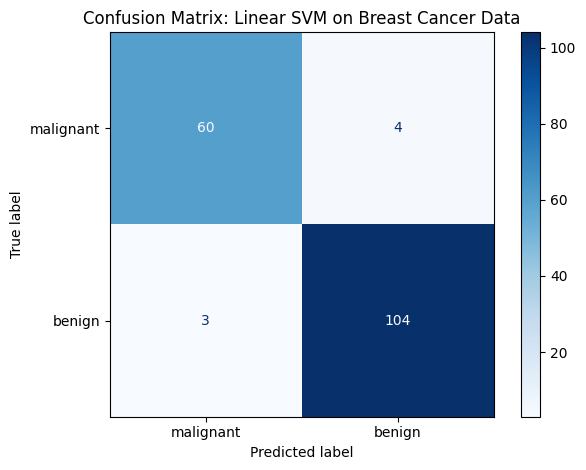

In [12]:
cm = confusion_matrix(y_test_cancer, cancer_predictions)
ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=cancer.target_names
).plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix: Linear SVM on Breast Cancer Data")
plt.tight_layout()
plt.show()

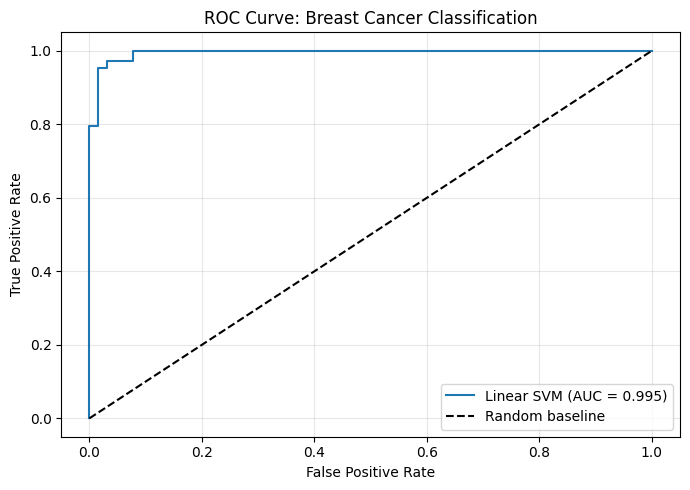

In [13]:
false_positive_rate, true_positive_rate, thresholds = roc_curve(
    y_test_cancer, cancer_probabilities
)
cancer_auc = roc_auc_score(y_test_cancer, cancer_probabilities)

plt.figure(figsize=(7, 5))
plt.plot(false_positive_rate, true_positive_rate,
         label=f"Linear SVM (AUC = {cancer_auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve: Breast Cancer Classification")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### How to interpret these metrics

- **Accuracy:** proportion of all test observations classified correctly.
- **Precision:** among observations predicted to be in a class, the fraction that truly belongs to that class.
- **Recall:** among observations that truly belong to a class, the fraction identified by the model.
- **F1-score:** harmonic mean of precision and recall.
- **Confusion matrix:** counts correct and incorrect predictions by actual and predicted class.
- **ROC curve:** plots true-positive rate against false-positive rate over thresholds.
- **AUC:** summarizes ROC performance across thresholds; larger values generally indicate better ranking discrimination.

For important applications, examine class-specific errors and validate the model on data representative of the intended use.

## Practical exercises

Use these exercises to check your understanding and modify the code above.

### Exercise 1: Build a simple SVM classifier
Train SVM classifiers on the Iris dataset with `linear`, `poly`, and `rbf` kernels. Report accuracy and the number of support vectors. Explain why the strongest kernel can vary by dataset.

### Exercise 2: Tune SVM parameters with grid search
Change the ranges of `C`, `degree`, and `gamma` in the grid search. Compare the best cross-validation score with the held-out test score. Explain why they may differ.

### Exercise 3: Visualize SVM decision boundaries
Use the two-feature Iris example. Try different values of `C` and `gamma`, and describe how the decision regions change.

### Additional challenge
Apply a scaling pipeline and an SVM to a dataset of your choice. Explain which metrics are appropriate for the task and why.

## Chapter Summary

This chapter introduced SVMs and kernel methods:

- SVM classification searches for a boundary with a wide margin; support vectors help define that boundary.
- `SVC` supports linear and nonlinear classification through kernels such as linear, polynomial, and RBF.
- `SVR` applies the support-vector approach to regression.
- `C`, `gamma`, and `degree` influence model flexibility and should be tuned with cross-validation.
- SVMs can handle high-dimensional data, but noisy or irrelevant features remain a challenge.
- Accuracy, precision, recall, F1-score, confusion matrices, ROC curves, and AUC provide complementary views of performance.
- Feature scaling is important for many SVM workflows, so a preprocessing pipeline is a useful practice.

**Reference:** Sukup, John. *scikit-learn Cookbook, Third Edition*. Chapter 7, “Support Vector Machines and Kernel Methods.”